# LSTM generation huis



In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [90]:
df= pd.read_parquet('../../prepared_data/forecast_targets_with_weather.parquet')
huis_generation = df[(df['location'] == 'huis') & (df['target_type'] == 'generation')]
huis_generation = huis_generation.dropna(subset=['pow_imputed'])

In [91]:
huis_generation.dtypes

timestamp           datetime64[ns, Europe/Amsterdam]
location                                      object
target_type                                   object
pow_w                                        float64
pow_imputed                                  float64
is_observed                                     bool
is_conflict                                     bool
is_imputed                                      bool
impute_methode                                object
Windrichting                                 float64
WindSnelheid                                 float64
Temperatuur                                  float64
GlobaleStraling                                int64
DuurNeerslag                                   int64
SomNeerslag                                  float64
LuchtVochtigheid                             float64
dtype: object

## voorspel instellingen

In [92]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7              # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op

TIME_COL = 'timestamp'   # pas aan naar de naam van jouw tijdkolom (of gebruik de index, zie onder)
tijd = pd.to_datetime(huis_generation[TIME_COL])
uur = tijd.dt.hour                                   # 0 t/m 23
dag_van_week = tijd.dt.dayofweek + uur / 24          # 0.0 t/m 6.96

huis_generation['uur_sin']  = np.sin(2 * np.pi * uur / 24)
huis_generation['uur_cos']  = np.cos(2 * np.pi * uur / 24)
huis_generation['week_sin'] = np.sin(2 * np.pi * dag_van_week / 7)
huis_generation['week_cos'] = np.cos(2 * np.pi * dag_van_week / 7)
TARGET_COL = 'pow_imputed'
FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos']   # target blijft op index 0                  # features (inclusief target)

TRAIN_FRAC = 0.60                    # deel van de data voor training
VAL_FRAC = 0.25                      # deel voor validatie data  ,de rest is test data

In [93]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

In [94]:
huis_generation['pow_imputed'].isna().value_counts()

pow_imputed
False    230726
Name: count, dtype: int64

## chronologisch splisen

In [95]:
values = huis_generation[FEATURE_COLS].values

n = len(values)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

## normaliseren

In [96]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

In [97]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [98]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 11297 | val: 4567 | test: 2645


Creeer DataLoader 

In [99]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

## training loop


In [100]:
hidden_sizes = [64,64]             # het aantal getallen van hidden size staat gelijk aan het aantal lagen 
dropout = 0.0                  
learning_rate = 1e-3
output_size = horizon           

class CustomLSTM(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(
                nn.LSTM(input_size=prev_size,
                        hidden_size=h,
                        num_layers=1,
                        batch_first=True)
            )
            prev_size = h


        self.fc = nn.Sequential(
            nn.Linear(hidden_sizes[-1], 128),
            nn.ReLU(),
            nn.Linear(128, output_size),    # laatste laag zonder ReLU, want opwek is negatief
        )

    def forward(self, x):
        out = x
        for lstm in self.layers:
            out, _ = lstm(out)
            out = self.dropout(out)

        out = out[:, -1, :]
        return self.fc(out)

model = CustomLSTM(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=horizon,
    dropout=0.2
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM LSTM |", sum(p.numel() for p in model.parameters()), "parameters")


CUSTOM LSTM | 171232 parameters


In [101]:
n_epochs = 20

train_loss_list = []
val_loss_list = []
epoch_time_list = []                                 


std_target = train_std[target_idx] 

if DEVICE == "cuda":                                  
    torch.cuda.synchronize()
start_totaal = time.perf_counter()                   #start tijd

beste_val = float("inf") 
beste_state = None

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()                 
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    if val_loss < beste_val:
        beste_val = val_loss
        beste_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    epoch_tijd = time.perf_counter() - start_epoch    # epoch train tijd berekenen
    epoch_time_list.append(epoch_tijd)

    print(f"Epoch {epoch+1}/{n_epochs}, "
          f"train loss: {train_loss:.4f} (echte MAE: {train_loss * std_target:.1f}), "   
          f"validation loss: {val_loss:.4f} (echte MAE: {val_loss * std_target:.1f}), " )

totale_tijd = time.perf_counter() - start_totaal      # totale tijd berekenen
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/20, train loss: 0.5204 (echte MAE: 326.5), validation loss: 0.4847 (echte MAE: 304.2), 
Epoch 2/20, train loss: 0.4246 (echte MAE: 266.5), validation loss: 0.4423 (echte MAE: 277.5), 
Epoch 3/20, train loss: 0.3954 (echte MAE: 248.1), validation loss: 0.4072 (echte MAE: 255.5), 
Epoch 4/20, train loss: 0.3971 (echte MAE: 249.2), validation loss: 0.4026 (echte MAE: 252.6), 
Epoch 5/20, train loss: 0.3773 (echte MAE: 236.8), validation loss: 0.3903 (echte MAE: 244.9), 
Epoch 6/20, train loss: 0.3719 (echte MAE: 233.4), validation loss: 0.3841 (echte MAE: 241.0), 
Epoch 7/20, train loss: 0.3684 (echte MAE: 231.2), validation loss: 0.3902 (echte MAE: 244.9), 
Epoch 8/20, train loss: 0.3657 (echte MAE: 229.5), validation loss: 0.4093 (echte MAE: 256.9), 
Epoch 9/20, train loss: 0.3645 (echte MAE: 228.7), validation loss: 0.3868 (echte MAE: 242.7), 
Epoch 10/20, train loss: 0.3659 (echte MAE: 229.6), validation loss: 0.3806 (echte MAE: 238.9), 
Epoch 11/20, train loss: 0.3688 (echte 

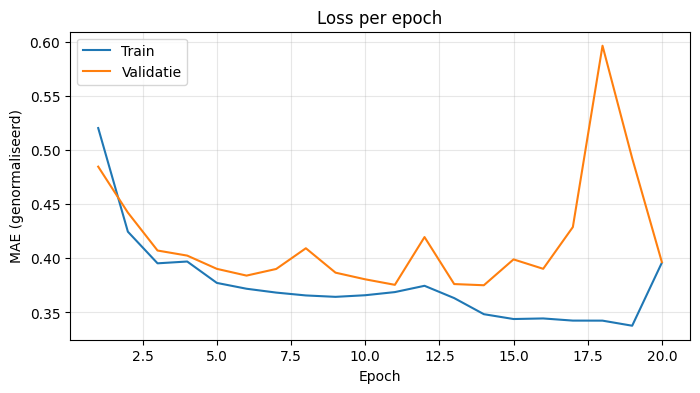

In [102]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

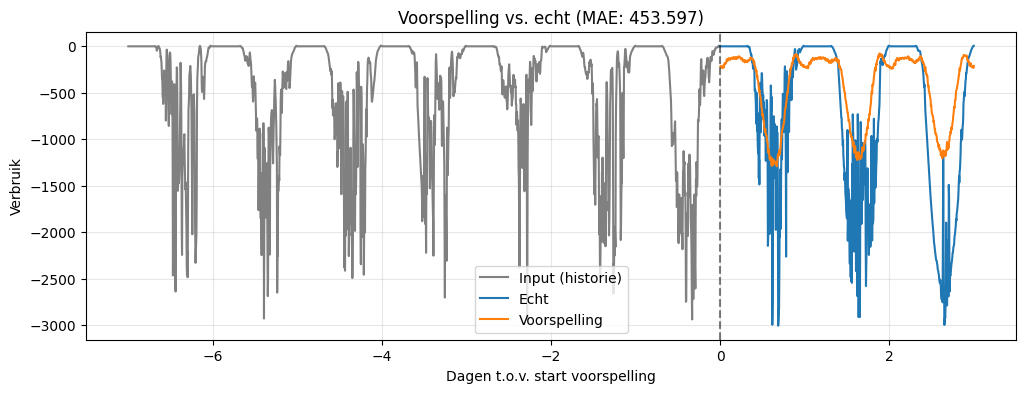

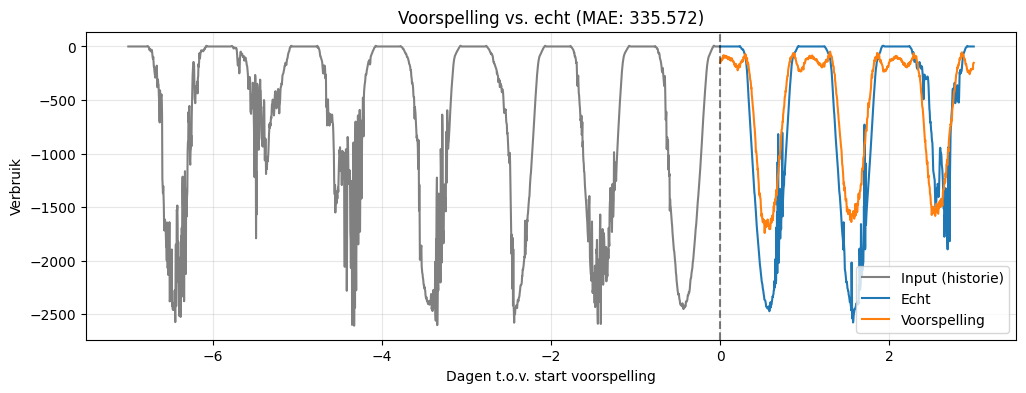

In [103]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment

MAE totaal: 313 W
Dag 1: 302 W
Dag 2: 314 W
Dag 3: 322 W


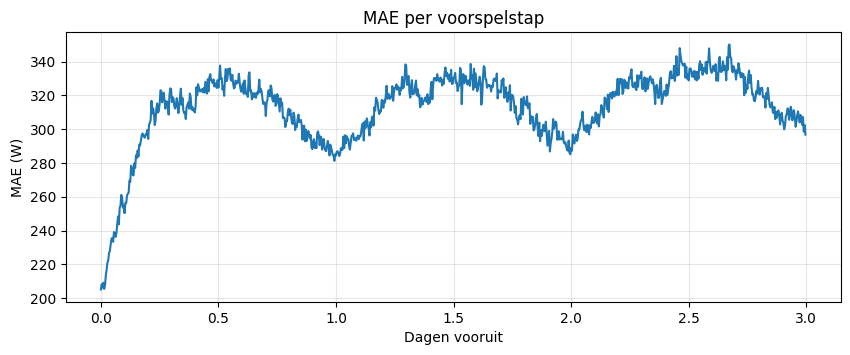

In [104]:
model.eval()
fouten = []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        fouten.append((model(inputs) - targets).abs().cpu())
fouten = torch.cat(fouten).numpy() * std_target     

mae_per_stap = fouten.mean(axis=0)
print(f"MAE totaal: {fouten.mean():.0f} W")
for d in range(aantal_dagen_forecast):
    s = slice(d * stap_per_dag, (d + 1) * stap_per_dag)
    print(f"Dag {d+1}: {mae_per_stap[s].mean():.0f} W")

plt.figure(figsize=(10, 3.5))
plt.plot(np.arange(horizon) / stap_per_dag, mae_per_stap)
plt.xlabel('Dagen vooruit')
plt.ylabel('MAE (W)')
plt.title('MAE per voorspelstap')
plt.grid(alpha=0.3)
plt.show()

In [107]:
from pathlib import Path

# --- Instellingen voor de resultatentabel ---
LOCATION = "huis"
TARGET_TYPE = "generation"
NOTEBOOK_NAAM = "lstm_generation_huis_weer"      
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

stappen_per_uur = 12                             # 12 metingen van 5 minuten = 1 uur
aantal_uren = horizon // stappen_per_uur         # 72 uur vooruit

# --- 1. Voorspellingen en baselines op alle testvensters (de test_loader schudt niet, de volgorde blijft gelijk) ---
model.eval()
preds, werkelijk, laatste_dag, laatste_waarde, gem_dag_7 = [], [], [], [], []
start = time.perf_counter()
with torch.no_grad():
    for inputs, targets in test_loader:
        preds.append(model(inputs.to(DEVICE)).cpu())
        werkelijk.append(targets)
        laatste_dag.append(inputs[:, -stap_per_dag:, target_idx])        # laatste 24 uur van de input
        laatste_waarde.append(inputs[:, -1, target_idx])                 # allerlaatste meting
        gem_dag_7.append(inputs[:, :, target_idx].reshape(-1, aantal_dagen_input, stap_per_dag).mean(dim=1))   # gemiddelde dag van de afgelopen 7 dagen
voorspeltijd = time.perf_counter() - start

# Terug naar Watt
m, s = train_mean[target_idx], train_std[target_idx]
def naar_watt(t):
    return torch.cat(t).numpy() * s + m

pred_w = naar_watt(preds)                                                         # (vensters, 864)
echt_w = naar_watt(werkelijk)
seasonal_w = np.tile(naar_watt(laatste_dag), (1, aantal_dagen_forecast))          # gisteren herhaald (24u)
last_w = np.repeat(naar_watt([x[:, None] for x in laatste_waarde]), horizon, axis=1)   # laatste waarde vastgehouden
gem_w = np.tile(naar_watt(gem_dag_7), (1, aantal_dagen_forecast))                 # gemiddelde dag, 3 keer herhaald

# --- 2. Per venster het tijdstip, en vensters met een gat in de tijd weglaten ---
tijd_alle = pd.to_datetime(huis_generation[TIME_COL]).reset_index(drop=True)      # zelfde volgorde als huis_generation
eerste_rij = i_val + np.array(test_dataset.starts)                                # eerste inputrij van elk testvenster
laatste_input_rij = eerste_rij + input_len - 1
laatste_rij = eerste_rij + input_len + horizon - 1

duur = tijd_alle.iloc[laatste_rij].to_numpy() - tijd_alle.iloc[eerste_rij].to_numpy()
zonder_gat = duur == np.timedelta64((input_len + horizon - 1) * 5, "m")
print(f"{zonder_gat.sum()} van {len(zonder_gat)} testvensters zonder gat in de tijd")
assert zonder_gat.any(), "Alle testvensters hebben een gat in de tijd: de testperiode is te kort of er ontbreken te veel metingen"

origin = tijd_alle.iloc[laatste_input_rij][zonder_gat].reset_index(drop=True)     # tijd van de laatste meting voor de voorspelling

# --- 3. Per uur gemiddeld, in lange vorm: een rij per venster en voorspeluur ---
def per_uur(a):
    a = a[zonder_gat]
    return a.reshape(len(a), aantal_uren, stappen_per_uur).mean(axis=2).ravel()

voorspellingen = pd.DataFrame({
    "origin": origin.repeat(aantal_uren).reset_index(drop=True),
    "horizon_h": np.tile(np.arange(1, aantal_uren + 1), len(origin)),
    "actual": per_uur(echt_w),
    "lstm": per_uur(pred_w),
    "seasonal_naive": per_uur(seasonal_w),
    "last": per_uur(last_w),
    "gemiddelde_dag": per_uur(gem_w),
})
voorspellingen.head()

2645 van 2645 testvensters zonder gat in de tijd


,origin,horizon_h,actual,lstm,seasonal_naive,last,gemiddelde_dag
0,2026-05-19 21:50:00+02:00,1,0.000002,-219.491832,0.229170,0.000002,0.066998
1,2026-05-19 21:50:00+02:00,2,0.000002,-180.567522,0.000002,0.000002,0.000039
2,2026-05-19 21:50:00+02:00,3,0.000002,-139.142815,0.000002,0.000002,0.000039
3,2026-05-19 21:50:00+02:00,4,0.000002,-126.593376,0.000002,0.000002,0.000039
4,2026-05-19 21:50:00+02:00,5,0.000002,-126.520074,0.000002,0.000002,0.000039


In [108]:
modelnamen = {"lstm": "lstm", "seasonal_naive": "Seasonal naive (24u)", "last": "Laatste waarde",
              "gemiddelde_dag": "Gemiddelde dag (7d)"}      # laatste regel is een extra baseline, haal hem weg als je hem niet wilt

# Dagelijkse voorspellingen: per kalenderdag de eerste voorspelling
origins = pd.Series(voorspellingen["origin"].unique()).sort_values()
kalenderdag = origins.dt.tz_convert("Europe/Amsterdam").dt.normalize()
dagelijkse_origins = origins.groupby(kalenderdag).first()

rijen = {}
for kolom, naam in modelnamen.items():
    fout = voorspellingen[kolom] - voorspellingen["actual"]
    res = {"MAE": fout.abs().mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for dag in range(3):
        deel = voorspellingen["horizon_h"].between(dag * 24 + 1, (dag + 1) * 24)
        res[f"MAE dag {dag + 1}"] = fout[deel].abs().mean()
    # Rolling: per dagelijkse forecast de MAE/RMSE, daarna gemiddeld
    dagelijks = voorspellingen["origin"].isin(dagelijkse_origins)
    per_venster = fout[dagelijks].groupby(voorspellingen.loc[dagelijks, "origin"])
    res["rolling MAE"] = per_venster.apply(lambda x: x.abs().mean()).mean()
    res["rolling RMSE"] = per_venster.apply(lambda x: np.sqrt((x ** 2).mean())).mean()
    rijen[naam] = res

resultaten = pd.DataFrame(rijen).T
resultaten.loc["gru", "trainingstijd (s)"] = totale_tijd          # uit de trainingscel
resultaten.loc["gru", "voorspeltijd (s)"] = voorspeltijd          # alle testvensters
resultaten = resultaten.round(1)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)"]
tijd_test = tijd_alle.iloc[i_val:]
resultaten["notebook"] = NOTEBOOK_NAAM
resultaten["locatie"] = LOCATION
resultaten["target"] = TARGET_TYPE
resultaten["resolutie"] = "5 min, beoordeeld per uur"             # of "1 uur", als de tabel overal dezelfde tekst moet hebben
resultaten["testperiode"] = f"{tijd_test.min():%Y-%m-%d} t/m {tijd_test.max():%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"{NOTEBOOK_NAAM}.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s)
lstm,lstm_generation_huis_weer,huis,generation,"5 min, beoordeeld per uur",2026-05-12 t/m 2026-09-10,281.0,391.6,269.3,282.6,291.0,297.7,393.3,NaN,NaN
Seasonal naive (24u),lstm_generation_huis_weer,huis,generation,"5 min, beoordeeld per uur",2026-05-12 t/m 2026-09-10,216.7,417.5,210.6,213.7,225.8,217.1,392.5,NaN,NaN
Laatste waarde,lstm_generation_huis_weer,huis,generation,"5 min, beoordeeld per uur",2026-05-12 t/m 2026-09-10,779.0,1066.7,771.1,781.4,784.3,611.8,946.5,NaN,NaN
Gemiddelde dag (7d),lstm_generation_huis_weer,huis,generation,"5 min, beoordeeld per uur",2026-05-12 t/m 2026-09-10,203.8,369.9,194.5,204.4,212.4,204.4,354.5,NaN,NaN
gru,lstm_generation_huis_weer,huis,generation,"5 min, beoordeeld per uur",2026-05-12 t/m 2026-09-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.6,0.6
